<a href="https://colab.research.google.com/github/edolio/ML_Projects/blob/main/LogisticRegression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
from google.colab import drive

# data are supposed to be in personal drive
drive.mount('/content/drive')

Mounted at /content/drive


In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, KFold, GridSearchCV, train_test_split, cross_validate
from sklearn import metrics
from sklearn.compose import ColumnTransformer
from sklearn.metrics import log_loss, ConfusionMatrixDisplay
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

import seaborn as sns
from pathlib import Path
from PIL import Image
import numpy as np
from matplotlib import pyplot as plt

label_cloudy = 1
label_desert = 2
label_green = 3
label_water = 4
class_names = ['cloudy', 'desert', 'green', 'water']   # must match the order of logisticRegr.classes_

**DATASET PREPARATION and MODEL INITIALIZATION**

Image shape is: (64, 64, 3)
Print example image



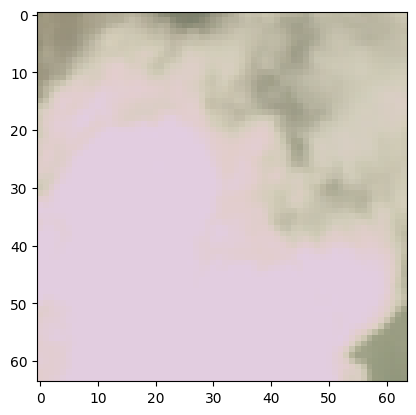

Input shape is: (5631, 12288)
Output shape is: (5631,)


In [4]:
# Image dimension is limited to 64x64 for RAM constraints
folder = Path('/content/drive/MyDrive/Training data/data/cloudy')  # change to your folder
paths = sorted(p for p in folder.iterdir() if p.suffix.lower() in {'.jpg', '.jpeg', '.png', '.bmp', '.gif', '.webp'})
images_cloudy = [np.array(Image.open(p).convert('RGB').resize((64, 64))) for p in paths]
Y = np.full(len(images_cloudy), label_cloudy)

folder = Path('/content/drive/MyDrive/Training data/data/desert')  # change to your folder
paths = sorted(p for p in folder.iterdir() if p.suffix.lower() in {'.jpg', '.jpeg', '.png', '.bmp', '.gif', '.webp'})
images_desert = [np.array(Image.open(p).convert('RGB').resize((64, 64))) for p in paths]
Y = np.concatenate([Y, np.full(len(images_desert), label_desert)])

folder = Path('/content/drive/MyDrive/Training data/data/green_area')  # change to your folder
paths = sorted(p for p in folder.iterdir() if p.suffix.lower() in {'.jpg', '.jpeg', '.png', '.bmp', '.gif', '.webp'})
images_green = [np.array(Image.open(p).convert('RGB').resize((64, 64))) for p in paths]
Y = np.concatenate([Y, np.full(len(images_green), label_green)])

folder = Path('/content/drive/MyDrive/Training data/data/water')  # change to your folder
paths = sorted(p for p in folder.iterdir() if p.suffix.lower() in {'.jpg', '.jpeg', '.png', '.bmp', '.gif', '.webp'})
images_water = [np.array(Image.open(p).convert('RGB').resize((64, 64))) for p in paths]
Y = np.concatenate([Y, np.full(len(images_water), label_water)])

print("Image shape is: " + str(images_cloudy[0].shape))
print("Print example image\n")
plt.imshow(images_cloudy[0], interpolation='nearest')
plt.show()

# data is normalized
X = np.stack(images_cloudy + images_desert + images_green + images_water,
             axis=0).reshape(len(Y), -1).astype('float32')

# delete unused arrays otherwise Colab collapses beacuse of lack of RAM
del images_cloudy, images_desert, images_green, images_water

print("Input shape is: " + str(X.shape))
print("Output shape is: " + str(Y.shape))

# model object initialization
# max_iter = 500 just for computation speed
logisticRegr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=500))

# useful function for later
def print_results(model, x_train, y_train, x_test, y_test, class_names):
    score = model.score(x_test, y_test)
    print(score)

    # plot confusion Matrix ----------------------------------------------
    y_pred = model.predict(x_test)
    fig, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, display_labels=class_names,
        normalize='true', values_format='.1%',
        cmap='Blues', colorbar=False, ax=ax)

    ax.set_title('Confusion matrix (test set)', fontsize=14, pad=12)
    ax.set_xlabel('Predicted', fontsize=12)
    ax.set_ylabel('True', fontsize=12)
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
    plt.tight_layout()
    plt.show()
    # plot confusion Matrix ----------------------------------------------

    train_loss = log_loss(y_train, model.predict_proba(x_train), labels=model.classes_)
    test_loss = log_loss(y_test, model.predict_proba(x_test), labels=model.classes_)

    print(f'train log loss: {train_loss:.4f}')
    print(f'test  log loss: {test_loss:.4f}')
    print(f'train acc: {model.score(x_train, y_train):.4f}   test acc: {model.score(x_test, y_test):.4f}')


**VALIDATION STEP - PERFORM STRATIFIED K-FOLD VALIDATION**



In [ ]:
skf = StratifiedKFold(n_splits=3, shuffle=True)


grid = GridSearchCV(
    logisticRegr,
    {'logisticregression__C': [0.01, 0.1, 1]},
    cv=skf,
    scoring={'acc': 'accuracy', 'll': 'neg_log_loss'},
    refit='acc',                 # best_estimator_ is chosen by accuracy
    return_train_score=True)
grid.fit(X, Y)

r = grid.cv_results_
for i, params in enumerate(r['params']):
    print(f"{params}  "
          f"acc train {r['mean_train_acc'][i]:.4f}  test {r['mean_test_acc'][i]:.4f} ± {r['std_test_acc'][i]:.4f}  |  "
          f"log loss train {-r['mean_train_ll'][i]:.4f}  test {-r['mean_test_ll'][i]:.4f} ± {r['std_test_ll'][i]:.4f}")

print('best C:', grid.best_params_, f'acc {grid.best_score_:.4f}')

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c

{'logisticregression__C': 0.1}  acc train 0.9660  test 0.8277 ± 0.0055  |  log loss train 0.1760  test 0.4803 ± 0.0148
{'logisticregression__C': 1}  acc train 0.9860  test 0.7954 ± 0.0051  |  log loss train 0.0948  test 0.8370 ± 0.0807
{'logisticregression__C': 10}  acc train 0.9913  test 0.7826 ± 0.0118  |  log loss train 0.0514  test 1.4917 ± 0.0564
best C: {'logisticregression__C': 0.1} acc 0.8277


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


'for name in [\'accuracy\', \'neg_log_loss\']:\n    tr, te = res[f\'train_{name}\'], res[f\'test_{name}\']\n    sign = -1 if name.startswith(\'neg\') else 1   # sklearn reports log loss as a negative number\n    print(f\'{name.replace("neg_", "")}: train {sign*tr.mean():.4f} ± {tr.std():.4f}   test {sign*te.mean():.4f} ± {te.std():.4f}\')'

**FINAL MODEL TRAIN AND TEST**

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


0.8402366863905325


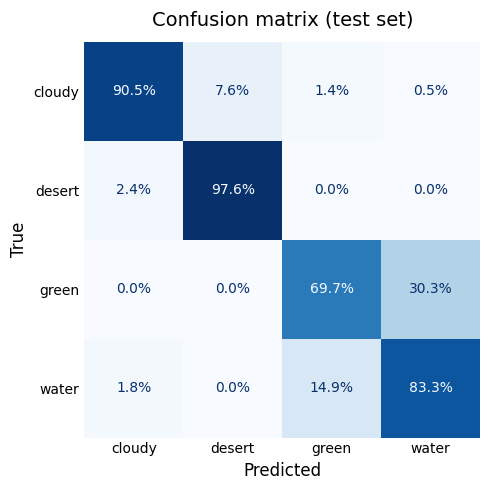

train log loss: 0.1806
test  log loss: 0.4404
train acc: 0.9626   test acc: 0.8402


In [ ]:
# change C according to validation
logisticRegr = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=500))

x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size=0.15, random_state=0)
logisticRegr.fit(x_train, y_train)

print_results(logisticRegr, x_train, y_train, x_test, y_test, class_names)

**VECTORIAL PCA IN PIPELINE - Repeat Validation**

In [6]:
logisticRegr = make_pipeline(StandardScaler(), PCA(n_components=0.95), LogisticRegression(max_iter=500))

skf = StratifiedKFold(n_splits=3, shuffle=True)


grid = GridSearchCV(
    logisticRegr,
    {'logisticregression__C': [0.001, 0.1, 100]},
    cv=skf,
    scoring={'acc': 'accuracy', 'll': 'neg_log_loss'},
    refit='acc',                 # best_estimator_ is chosen by accuracy
    return_train_score=True)
grid.fit(X, Y)

r = grid.cv_results_
for i, params in enumerate(r['params']):
    print(f"{params}  "
          f"acc train {r['mean_train_acc'][i]:.4f}  test {r['mean_test_acc'][i]:.4f} ± {r['std_test_acc'][i]:.4f}  |  "
          f"log loss train {-r['mean_train_ll'][i]:.4f}  test {-r['mean_test_ll'][i]:.4f} ± {r['std_test_ll'][i]:.4f}")

print('best C:', grid.best_params_, f'acc {grid.best_score_:.4f}')

KeyboardInterrupt: 

**Train Final Model with PCA**

0.8201183431952662


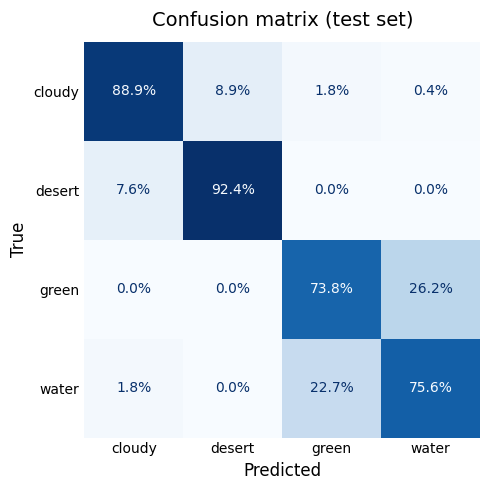

train log loss: 0.4053
test  log loss: 0.4157
train acc: 0.8228   test acc: 0.8201


In [15]:
logisticRegr = make_pipeline(StandardScaler(), PCA(n_components=0.95), LogisticRegression(C=0.1,max_iter=500))

x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size=0.15, random_state=0, stratify=Y)
logisticRegr.fit(x_train, y_train)

print_results(logisticRegr, x_train, y_train, x_test, y_test, class_names)

**TEXTURE FEAUTURE** - We will add a feature based on texture difference between green and water images

In [7]:
def texture_features(X_flat, size=64):
    g = X_flat.reshape(-1, size, size, 3).astype('float32').mean(axis=3)  # greyscale, shape (N, size, size)
    dx = np.abs(np.diff(g, axis=2))   # difference between each pixel and its right neighbour
    dy = np.abs(np.diff(g, axis=1))   # difference between each pixel and the one below
    return np.column_stack([
        dx.mean(axis=(1, 2)), dy.mean(axis=(1, 2)),   # average graininess
        dx.std(axis=(1, 2)),  dy.std(axis=(1, 2)),    # is the graininess uniform or patchy?
        g.std(axis=(1, 2)),                           # overall contrast
    ])

T = texture_features(X)   # shape (5631, 5)

# if class 3 and 4 show different numbers, texture feature will be effective
for c in np.unique(Y):
    print(c, T[Y == c].mean(axis=0).round(1))

1 [1.7 1.7 1.7 1.6 9.3]
2 [1.4 1.5 1.4 1.7 3.5]
3 [1.9 1.9 1.9 1.9 3.5]
4 [0.8 0.8 1.1 1.1 2.7]


In [10]:
n_pix = X.shape[1]
X_all = np.hstack([X.astype('float32'), T])

pre = ColumnTransformer([
    ('pixels',  make_pipeline(StandardScaler(), PCA(n_components=0.95)), slice(0, n_pix)),
    ('texture', StandardScaler(), slice(n_pix, None)),
])

logisticRegr = make_pipeline(pre, LogisticRegression(C=0.1, max_iter=500))

x_train, x_test, y_train, y_test = train_test_split(X_all, Y, test_size=0.15, random_state=0, stratify=Y)
logisticRegr.fit(x_train, y_train)

print_results(logisticRegr, x_train, y_train, x_test, y_test, class_names)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('pixels',
                                                  Pipeline(steps=[('standardscaler',
                                                                   StandardScaler()),
                                                                  ('pca',
                                                                   PCA(n_components=0.95))]),
                                                  slice(0, 12288, None)),
                                                 ('texture', StandardScaler(),
                                                  slice(12288, None, None))])),
                ('logisticregression',
                 LogisticRegression(C=0.01, max_iter=500))])